# FleetReliability-AI — Phase 1: Idempotent Data Ingestion, Physics Feature Engineering & Leakage-Free EDA

**Project:** Condition-Based Maintenance (CBM) Predictive System for Industrial & Mining Assets  
**Dataset:** UCI AI4I 2020 Predictive Maintenance Telemetry ($N = 10{,}000$, 14 base columns)  
**Notebook Scope:** Phase 1 End-to-End Pipeline — Ingestion Verification, Leakage-Free 80/20 Stratified Split Persistence, Exploratory Data Analysis (Phases A–E), Causal Physics Validation, and Initial 5-Fold Stratified Baseline (`LogisticRegression`).

---

## Business & Reliability Context

In heavy manufacturing and mining operations (SAG mills, slurry pumps, haulage equipment, and CNC machining centers), unscheduled mechanical failures impose severe asymmetric costs:
- **Unplanned Downtime & Collateral Damage (False Negatives):** Sudden failures halt production lines ($\$1{,}500$–$\$3{,}750	ext{ USD/hr}$ depending on asset criticality, reaching $> \$10{,}000	ext{ USD/hr}$ in critical bottlenecks) alongside expensive secondary repairs.
- **Unnecessary Preventive Inspections (False Positives):** Triggering non-destructive CBM inspections on healthy assets consumes specialized labor hours ($pprox \$350	ext{ USD}$ per inspection).

> **Strict Anti-Leakage Protocol:** The 20% `test_holdout` partition (`data/processed/test_holdout.csv`, $N = 2{,}000$) is locked immediately after stratified splitting and is **never** accessed for feature statistics, exploratory tuning, or Phase 1 baseline evaluation. Post-mortem root-cause columns (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) and identifiers (`UDI`, `Product ID`) are strictly excluded from modeling matrices.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import kurtosis, skew
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Resolve repository root reliably whether executed from root or notebooks/
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.constants import RANDOM_STATE
from src.data_loader import load_raw_data
from src.features import (
    FAILURE_MODES,
    PHYSICAL_FEATURE_COLUMNS,
    RAW_FEATURE_COLUMNS,
    TARGET_COLUMN,
    PhysicalFeatureTransformer,
    normalize_raw_dataframe,
    prepare_training_matrices,
)

# Visual styling
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RAW_DATA_FILE = PROJECT_ROOT / "data" / "raw" / "ai4i2020.csv"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project Root : {PROJECT_ROOT.name}")
print(f"Pandas       : {pd.__version__}")
print(f"NumPy        : {np.__version__}")
print(f"RANDOM_STATE : {RANDOM_STATE}")

Project Root : fleetreliability-ai
Pandas       : 3.1.1
NumPy        : 2.4.6
RANDOM_STATE : 42


## 1. Idempotent Data Ingestion & Leakage-Free 80/20 Stratified Split Persistence

We verify `data/raw/ai4i2020.csv` via `load_raw_data()` (UTF-8 BOM handling + shape validation) and invoke `prepare_training_matrices(..., test_size=0.2, random_state=42)` to generate and persist:
- `data/processed/train_dev.csv` ($8{,}000$ rows, 80% development set)
- `data/processed/test_holdout.csv` ($2{,}000$ rows, 20% locked holdout set)

Both files include normalized `snake_case` raw features, the 4 derived physics features, and the binary target `machine_failure`, while strictly excluding identifiers (`UDI`, `Product ID`) and post-mortem diagnostic flags (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`).

In [2]:
assert RAW_DATA_FILE.exists(), f"Missing raw dataset at {RAW_DATA_FILE}"
df_raw = load_raw_data(data_path=RAW_DATA_FILE)
assert df_raw.shape == (10_000, 14), f"Unexpected raw shape: {df_raw.shape}"

# Leakage-free 80/20 stratified split
x_train_dev, x_test, y_train_dev, y_test = prepare_training_matrices(
    df_raw,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

train_dev_df = x_train_dev.copy()
train_dev_df[TARGET_COLUMN] = y_train_dev.values

test_holdout_df = x_test.copy()
test_holdout_df[TARGET_COLUMN] = y_test.values

train_dev_path = PROCESSED_DIR / "train_dev.csv"
test_holdout_path = PROCESSED_DIR / "test_holdout.csv"

train_dev_df.to_csv(train_dev_path, index=False)
test_holdout_df.to_csv(test_holdout_path, index=False)

# Verification audit of persisted splits
assert len(train_dev_df) == 8_000, f"Expected 8000 rows, got {len(train_dev_df)}"
assert len(test_holdout_df) == 2_000, f"Expected 2000 rows, got {len(test_holdout_df)}"

forbidden_cols = {"UDI", "Product ID", *FAILURE_MODES}
assert forbidden_cols.isdisjoint(train_dev_df.columns), "Leakage column detected in train_dev!"
assert forbidden_cols.isdisjoint(test_holdout_df.columns), "Leakage column detected in test_holdout!"

split_summary = pd.DataFrame(
    {
        "Split": ["train_dev (80%)", "test_holdout (20% - LOCKED)"],
        "Rows": [len(train_dev_df), len(test_holdout_df)],
        "Columns": [train_dev_df.shape[1], test_holdout_df.shape[1]],
        "Failures (n)": [int(y_train_dev.sum()), int(y_test.sum())],
        "Failure Rate (%)": [
            round(float(y_train_dev.mean()) * 100, 3),
            round(float(y_test.mean()) * 100, 3),
        ],
    }
)
display(split_summary)
print(f"Saved: {train_dev_path.relative_to(PROJECT_ROOT)}")
print(f"Saved: {test_holdout_path.relative_to(PROJECT_ROOT)} (locked — will NOT be used for modeling)")

2026-11-15T20:03:52 | INFO     | fleetreliability:load_raw_data:172 - Loaded raw telemetry dataset from /home/Martin/Repos_Git/fleetreliability-ai/data/raw/ai4i2020.csv with shape (10000, 14).


2026-11-15T20:03:52 | INFO     | fleetreliability.features:prepare_training_matrices:430 - Prepared stratified split: train_dev=8000 rows, test_holdout=2000 rows.


,Split,Rows,Columns,Failures (n),Failure Rate (%)
0,train_dev (80%),8000,11,271,3.388
1,test_holdout (20% - LOCKED),2000,11,68,3.400


Saved: data/processed/train_dev.csv
Saved: data/processed/test_holdout.csv (locked — will NOT be used for modeling)


---

## 2. Phase A — Structural Integrity & Data Quality Audit

We audit the raw dataset `(10000, 14)` for:
1. Exact schema and column types using `select_dtypes(include=["object", "string", "str"])` (compatible with `pandas 3.1.1` `StringDtype`) and `select_dtypes(include="number")`.
2. Missing values across all 14 columns.
3. Primary key uniqueness (`UDI`, `Product ID`).
4. Physical sensor bounds against industrial safety envelopes:
   - $T_{\text{air}} \in [295.0, 305.0]\text{ K}$
   - $T_{\text{process}} \in [305.0, 315.0]\text{ K}$
   - $\text{Rotational speed} \in [1100, 2900]\text{ rpm}$
   - $\text{Torque} \in [3.5, 80.0]\text{ Nm}$
   - $\text{Tool wear} \in [0, 260]\text{ min}$

In [3]:
print(f"Dataset shape: {df_raw.shape}")
print(f"Unique UDI count: {df_raw['UDI'].nunique()} / {len(df_raw)}")
print(f"Unique Product ID count: {df_raw['Product ID'].nunique()} / {len(df_raw)}")
print(f"Exact duplicate rows: {df_raw.duplicated().sum()}")

# pandas 3.1.1 StringDtype-compatible dtype inspection
text_cols = df_raw.select_dtypes(include=["object", "string", "str"]).columns.tolist()
num_cols_raw = df_raw.select_dtypes(include="number").columns.tolist()
print(f"Text / categorical columns (object/string/str): {text_cols}")
print(f"Numeric columns: {num_cols_raw}")

# Null & dtype audit table
schema_audit = pd.DataFrame(
    {
        "Column": df_raw.columns,
        "Dtype": [str(dt) for dt in df_raw.dtypes],
        "Non-Null Count": df_raw.notna().sum().values,
        "Missing Count": df_raw.isna().sum().values,
        "Unique Values": [df_raw[c].nunique() for c in df_raw.columns],
    }
)
display(schema_audit)

# Physical bounds validation
physical_bounds = {
    "Air temperature [K]": (295.0, 305.0),
    "Process temperature [K]": (305.0, 315.0),
    "Rotational speed [rpm]": (1100.0, 2900.0),
    "Torque [Nm]": (3.5, 80.0),
    "Tool wear [min]": (0.0, 260.0),
}

range_rows = []
for col, (low, high) in physical_bounds.items():
    col_min = float(df_raw[col].min())
    col_max = float(df_raw[col].max())
    out_of_bounds = int(((df_raw[col] < low) | (df_raw[col] > high)).sum())
    range_rows.append(
        {
            "Sensor Variable": col,
            "Observed Min": round(col_min, 2),
            "Observed Max": round(col_max, 2),
            "Expected Lower": low,
            "Expected Upper": high,
            "Out-of-Bounds Count": out_of_bounds,
            "Status": "PASS" if out_of_bounds == 0 else "FAIL",
        }
    )

range_audit_df = pd.DataFrame(range_rows)
display(range_audit_df)
assert (range_audit_df["Out-of-Bounds Count"] == 0).all(), "Physical sensor bounds violated!"

Dataset shape: (10000, 14)
Unique UDI count: 10000 / 10000
Unique Product ID count: 10000 / 10000
Exact duplicate rows: 0
Text / categorical columns (object/string/str): ['Product ID', 'Type']
Numeric columns: ['UDI', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


,Column,Dtype,Non-Null Count,Missing Count,Unique Values
0,UDI,int64,10000,0,10000
1,Product ID,str,10000,0,10000
2,Type,str,10000,0,3
3,Air temperature [K],float64,10000,0,93
4,Process temperature [K],float64,10000,0,82
5,Rotational speed [rpm],int64,10000,0,941
6,Torque [Nm],float64,10000,0,577
7,Tool wear [min],int64,10000,0,246
8,Machine failure,int64,10000,0,2
9,TWF,int64,10000,0,2


,Sensor Variable,Observed Min,Observed Max,Expected Lower,Expected Upper,Out-of-Bounds Count,Status
0,Air temperature [K],295.3,304.5,295.0,305.0,0,PASS
1,Process temperature [K],305.7,313.8,305.0,315.0,0,PASS
2,Rotational speed [rpm],1168.0,2886.0,1100.0,2900.0,0,PASS
3,Torque [Nm],3.8,76.6,3.5,80.0,0,PASS
4,Tool wear [min],0.0,253.0,0.0,260.0,0,PASS


---

## 3. Phase B — Univariate Analysis & Telemetry Distributions

We examine the target class imbalance (`Machine failure`) and analyze the distribution shape (histograms with KDE, skewness, excess kurtosis, and failure-conditioned boxplots) across all raw and derived physical telemetry features.

Normal operations (0): 9,661 (96.61%)
Machine failures  (1): 339 (3.39%)
Imbalance Ratio      : 28.50 : 1


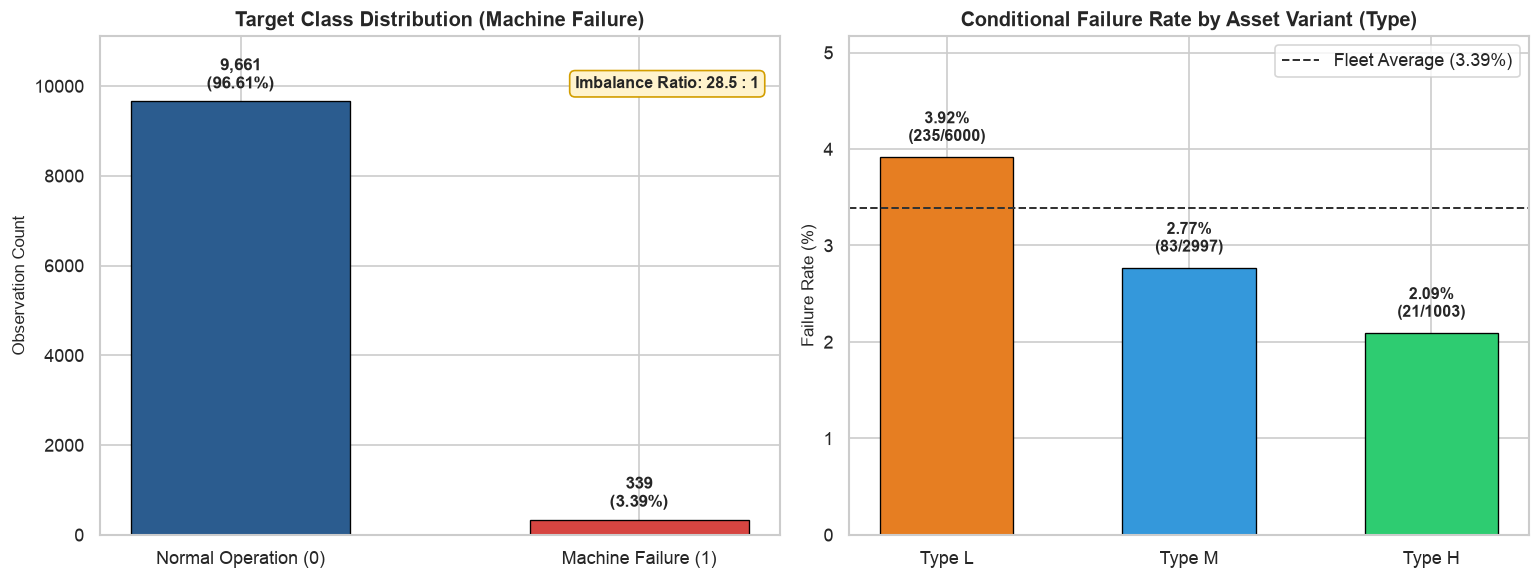

Exported: reports/figures/01_target_imbalance.png


In [4]:
# Create EDA DataFrame with normalized names and derived physics features
df_eda = PhysicalFeatureTransformer().fit_transform(normalize_raw_dataframe(df_raw))

target_counts = df_eda[TARGET_COLUMN].value_counts().sort_index()
n_neg = int(target_counts[0])
n_pos = int(target_counts[1])
imbalance_ratio = n_neg / n_pos

print(f"Normal operations (0): {n_neg:,} ({n_neg / len(df_eda) * 100:.2f}%)")
print(f"Machine failures  (1): {n_pos:,} ({n_pos / len(df_eda) * 100:.2f}%)")
print(f"Imbalance Ratio      : {imbalance_ratio:.2f} : 1")

# Export Figure 01: Target Imbalance & Asset Variant Failure Rate
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel A: Target class distribution
labels = ["Normal Operation (0)", "Machine Failure (1)"]
counts = [n_neg, n_pos]
colors = ["#2b5c8f", "#d64541"]
bars = axes[0].bar(labels, counts, color=colors, width=0.55, edgecolor="black", linewidth=0.8)
axes[0].set_title("Target Class Distribution (Machine Failure)", fontweight="bold")
axes[0].set_ylabel("Observation Count")
axes[0].set_ylim(0, n_neg * 1.15)
for bar, count in zip(bars, counts):
    pct = count / len(df_eda) * 100
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 180,
        f"{count:,}\n({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )
axes[0].text(
    0.97,
    0.92,
    f"Imbalance Ratio: {imbalance_ratio:.1f} : 1",
    transform=axes[0].transAxes,
    ha="right",
    va="top",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="#fff3cd", edgecolor="#d39e00"),
    fontsize=9.5,
    fontweight="bold",
)

# Panel B: Conditional failure rate by machine_type
type_order = ["L", "M", "H"]
type_stats = (
    df_eda.groupby("machine_type")[TARGET_COLUMN]
    .agg(["count", "sum", "mean"])
    .reindex(type_order)
)
rates_pct = type_stats["mean"] * 100
type_colors = ["#e67e22", "#3498db", "#2ecc71"]
bars_t = axes[1].bar(
    [f"Type {t}" for t in type_order],
    rates_pct,
    color=type_colors,
    width=0.55,
    edgecolor="black",
    linewidth=0.8,
)
axes[1].axhline(
    df_eda[TARGET_COLUMN].mean() * 100,
    color="#333333",
    linestyle="--",
    linewidth=1.2,
    label=f"Fleet Average ({df_eda[TARGET_COLUMN].mean() * 100:.2f}%)",
)
axes[1].set_title("Conditional Failure Rate by Asset Variant (Type)", fontweight="bold")
axes[1].set_ylabel("Failure Rate (%)")
axes[1].set_ylim(0, rates_pct.max() * 1.32)
axes[1].legend(loc="upper right")
for bar, (_, row) in zip(bars_t, type_stats.iterrows()):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.12,
        f"{row['mean'] * 100:.2f}%\n({int(row['sum'])}/{int(row['count'])})",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold",
    )

plt.tight_layout()
fig01_path = FIGURES_DIR / "01_target_imbalance.png"
fig.savefig(fig01_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Exported: {fig01_path.relative_to(PROJECT_ROOT)}")

,Feature,Mean,Std,Min,Median,Max,Skewness,Excess Kurtosis
0,air_temperature_k,300.005,2.000,295.300,300.100,304.500,0.114,-0.836
1,process_temperature_k,310.006,1.484,305.700,310.100,313.800,0.015,-0.500
2,rotational_speed_rpm,1538.776,179.284,1168.000,1503.000,2886.000,1.993,7.389
3,torque_nm,39.987,9.969,3.800,40.100,76.600,-0.010,-0.014
4,tool_wear_min,107.951,63.654,0.000,108.000,253.000,0.027,-1.167
5,mechanical_power_kw,6.280,1.067,1.148,6.271,10.470,0.008,0.157
6,temperature_difference_k,10.001,1.001,7.600,9.800,12.100,-0.072,-0.986
7,strain_index_min_nm,4314.665,2826.568,0.000,4012.950,16497.000,0.469,-0.464
8,heat_stress_ratio,6.576,0.941,2.840,6.574,9.462,-0.159,-0.066


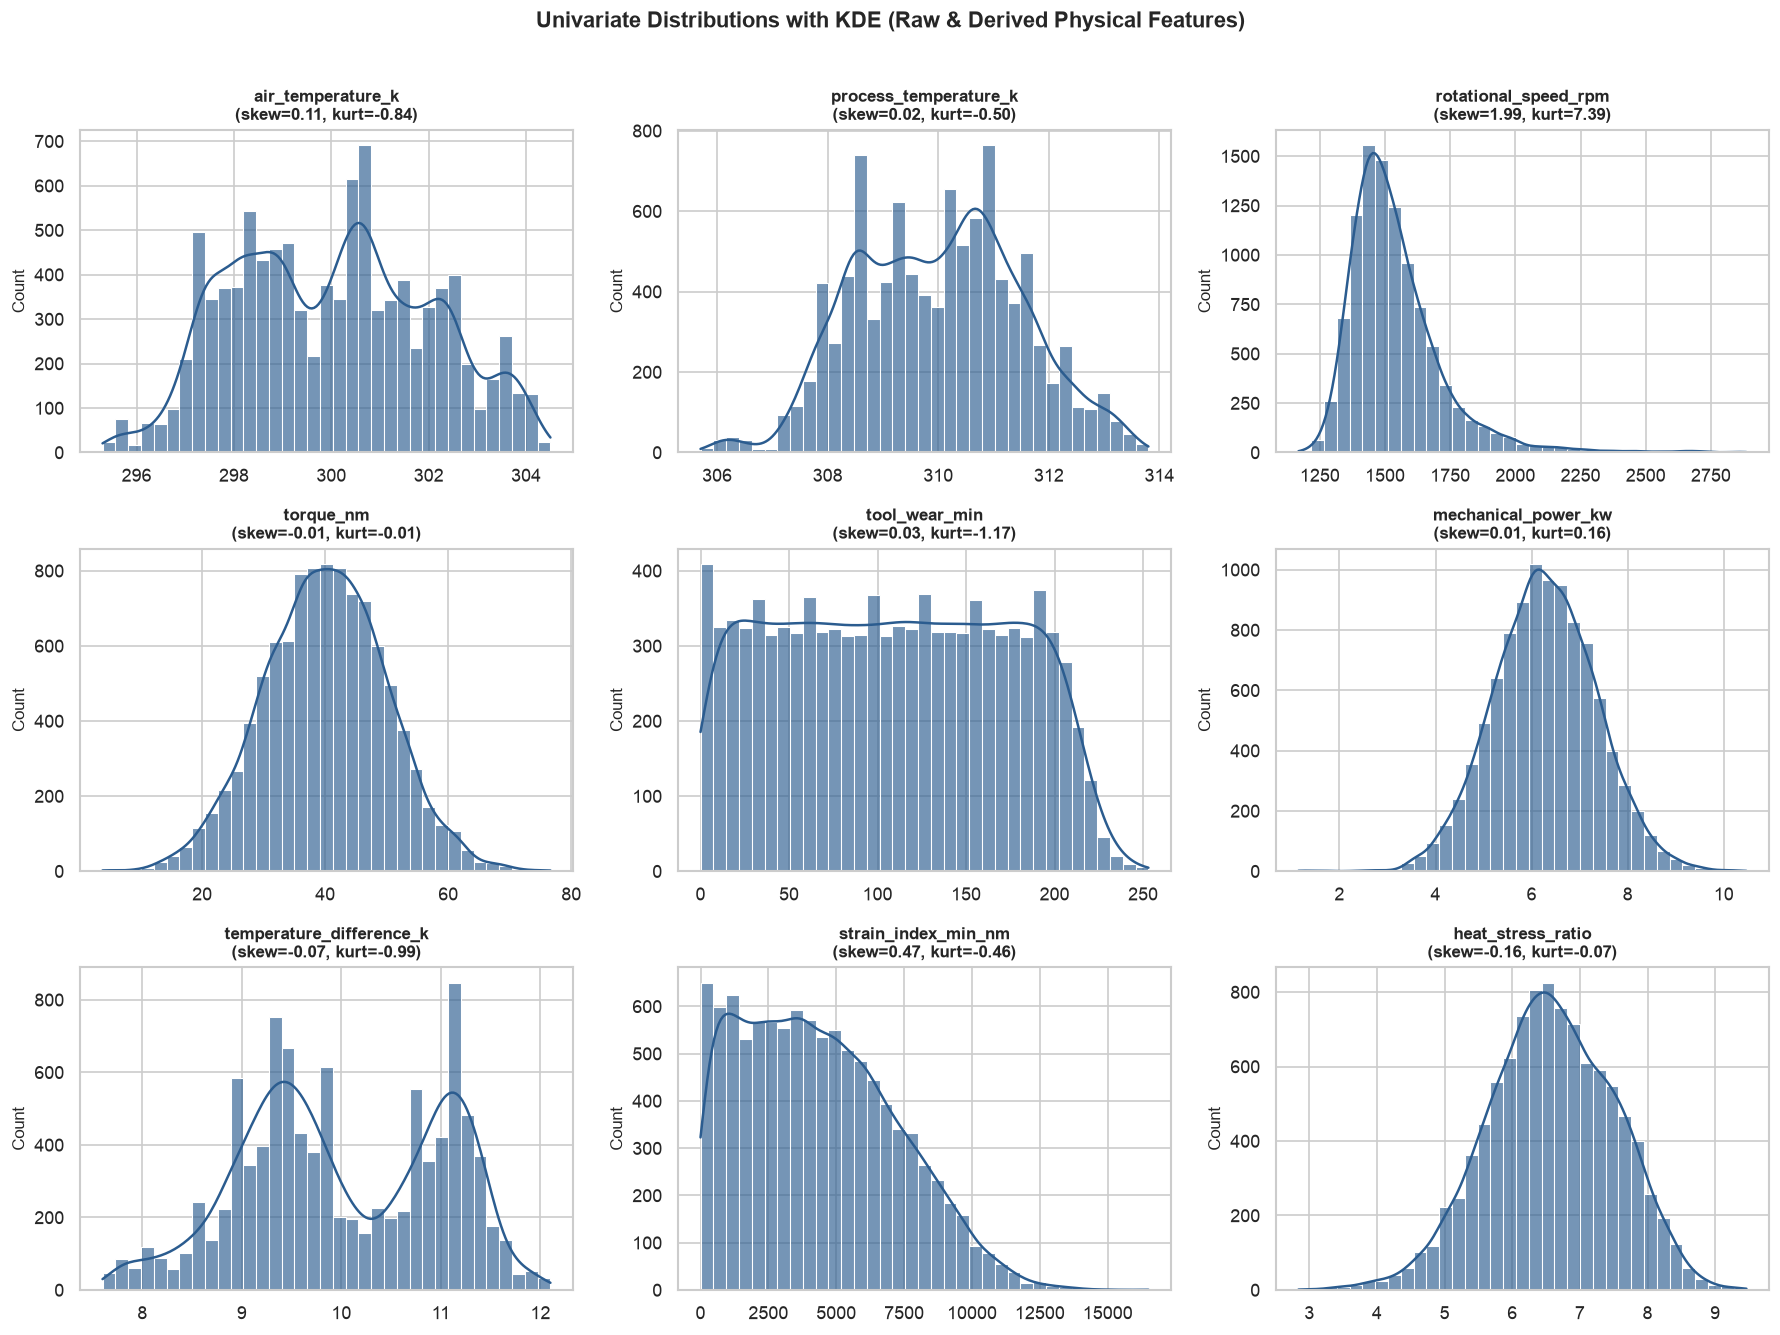

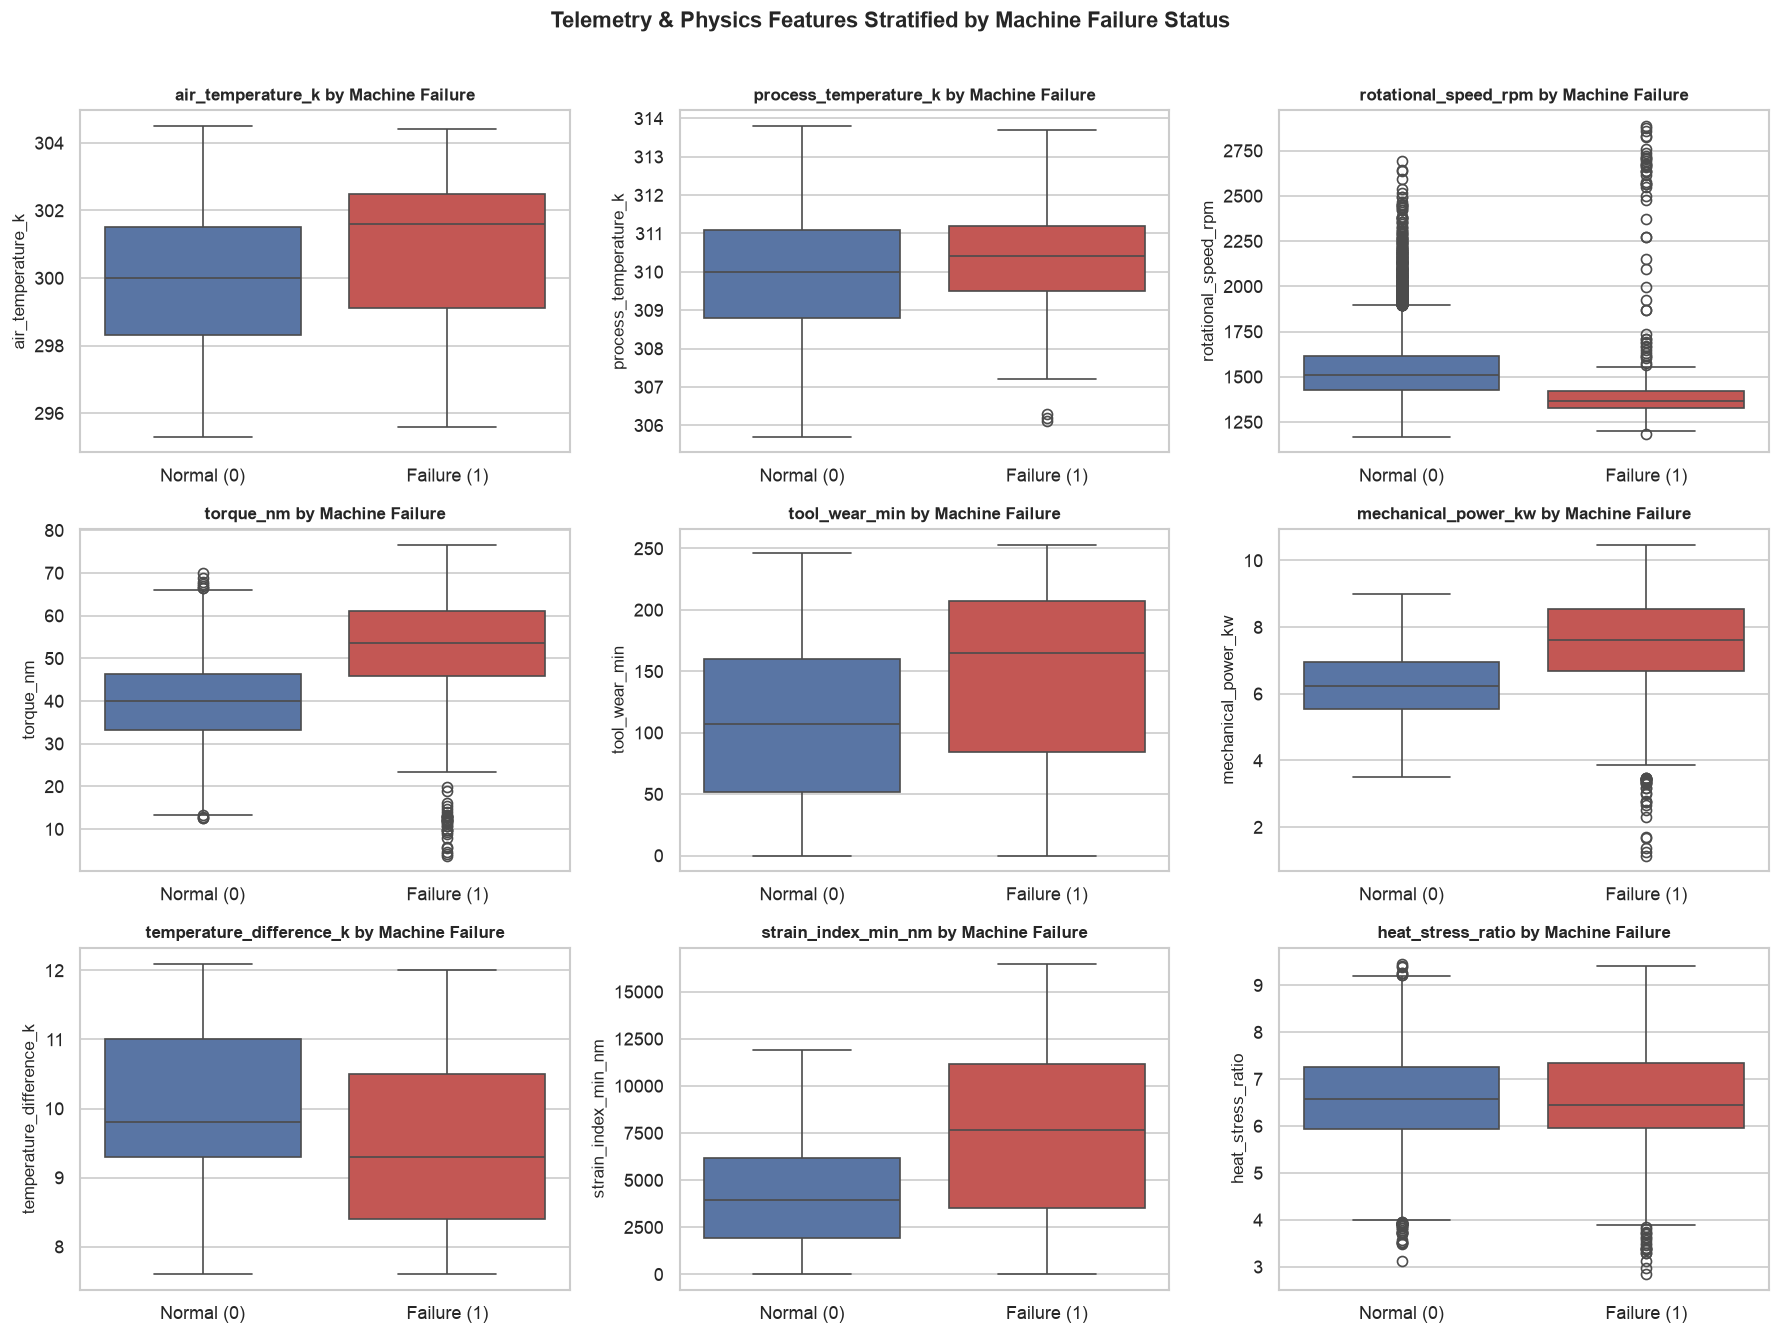

In [5]:
# Univariate Summary Statistics: Mean, Std, Quantiles, Skewness & Kurtosis
continuous_features = [
    "air_temperature_k",
    "process_temperature_k",
    "rotational_speed_rpm",
    "torque_nm",
    "tool_wear_min",
] + PHYSICAL_FEATURE_COLUMNS

stats_rows = []
for col in continuous_features:
    series = df_eda[col].dropna()
    stats_rows.append(
        {
            "Feature": col,
            "Mean": round(float(series.mean()), 3),
            "Std": round(float(series.std()), 3),
            "Min": round(float(series.min()), 3),
            "Median": round(float(series.median()), 3),
            "Max": round(float(series.max()), 3),
            "Skewness": round(float(skew(series)), 3),
            "Excess Kurtosis": round(float(kurtosis(series)), 3),
        }
    )

univariate_stats_df = pd.DataFrame(stats_rows)
display(univariate_stats_df)

# Histograms with KDE across all 9 continuous features
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()
for idx, col in enumerate(continuous_features):
    sns.histplot(
        data=df_eda,
        x=col,
        kde=True,
        bins=35,
        ax=axes[idx],
        color="#2b5c8f",
        alpha=0.65,
    )
    s_val = float(skew(df_eda[col]))
    k_val = float(kurtosis(df_eda[col]))
    axes[idx].set_title(f"{col}\n(skew={s_val:.2f}, kurt={k_val:.2f})", fontsize=10, fontweight="bold")
    axes[idx].set_xlabel("")
plt.suptitle("Univariate Distributions with KDE (Raw & Derived Physical Features)", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# Boxplots grouped by Machine Failure status
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()
for idx, col in enumerate(continuous_features):
    sns.boxplot(
        data=df_eda,
        x=TARGET_COLUMN,
        y=col,
        hue=TARGET_COLUMN,
        palette={0: "#4c72b0", 1: "#d64541"},
        legend=False,
        ax=axes[idx],
    )
    axes[idx].set_title(f"{col} by Machine Failure", fontsize=10, fontweight="bold")
    axes[idx].set_xticks([0, 1])
    axes[idx].set_xticklabels(["Normal (0)", "Failure (1)"])
    axes[idx].set_xlabel("")
plt.suptitle("Telemetry & Physics Features Stratified by Machine Failure Status", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

---

## 4. Phase C — Bivariate, Multivariate Correlation & Mutual Information

We evaluate:
1. **Pearson Linear Correlation ($r$):** Captures linear collinearity (notably the positive thermal coupling between `air_temperature_k` and `process_temperature_k`, and the inverse hyperbolic trade-off between `rotational_speed_rpm` and `torque_nm`).
2. **Spearman Rank Correlation ($\rho$):** Captures monotonic non-linear associations.
3. **Mutual Information (`mutual_info_classif`):** Captures arbitrary non-linear statistical dependencies between each continuous feature and the binary target `machine_failure`.

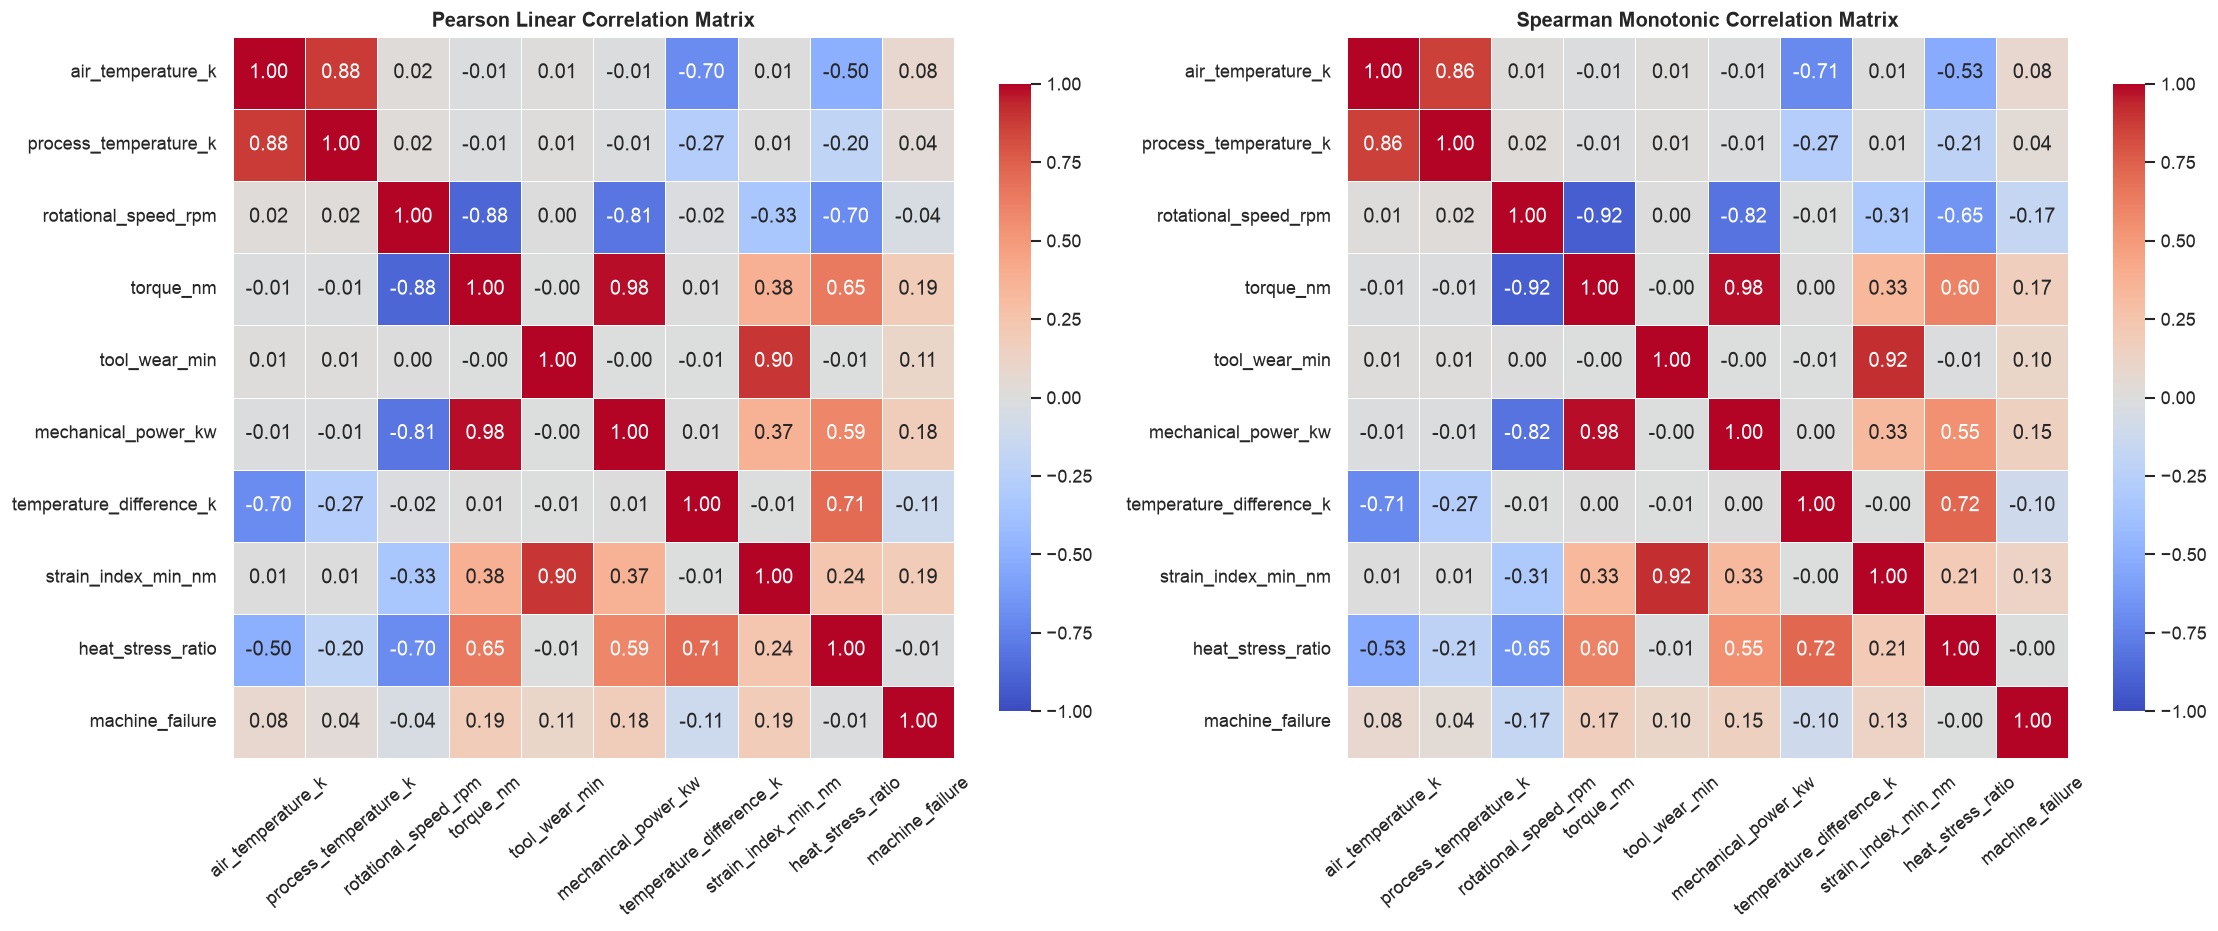

Exported: reports/figures/02_correlation_matrix.png


,Feature,Pearson_r_target,Spearman_rho_target,Mutual_Info
0,torque_nm,0.1913,0.1694,0.0464
1,mechanical_power_kw,0.1760,0.1540,0.0446
2,rotational_speed_rpm,-0.0442,-0.1672,0.0356
3,strain_index_min_nm,0.1904,0.1282,0.0342
4,heat_stress_ratio,-0.0095,-0.0001,0.0140
5,tool_wear_min,0.1054,0.1016,0.0130
6,temperature_difference_k,-0.1117,-0.1018,0.0118
7,air_temperature_k,0.0826,0.0832,0.0047
8,process_temperature_k,0.0359,0.0399,0.0018


Key collinearity check — Air vs Process Temp Pearson r = 0.8761
Key collinearity check — Speed vs Torque Pearson r = -0.8750 (Spearman rho = -0.9165)


In [6]:
corr_cols = continuous_features + [TARGET_COLUMN]
pearson_corr = df_eda[corr_cols].corr(method="pearson")
spearman_corr = df_eda[corr_cols].corr(method="spearman")

# Export Figure 02: Side-by-Side Pearson and Spearman Correlation Matrices
fig, axes = plt.subplots(1, 2, figsize=(19, 8))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0.0,
    vmin=-1.0,
    vmax=1.0,
    linewidths=0.4,
    square=True,
    cbar_kws={"shrink": 0.78},
    ax=axes[0],
)
axes[0].set_title("Pearson Linear Correlation Matrix", fontsize=12, fontweight="bold")
axes[0].tick_params(axis="x", rotation=40)

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0.0,
    vmin=-1.0,
    vmax=1.0,
    linewidths=0.4,
    square=True,
    cbar_kws={"shrink": 0.78},
    ax=axes[1],
)
axes[1].set_title("Spearman Monotonic Correlation Matrix", fontsize=12, fontweight="bold")
axes[1].tick_params(axis="x", rotation=40)

plt.tight_layout()
fig02_path = FIGURES_DIR / "02_correlation_matrix.png"
fig.savefig(fig02_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Exported: {fig02_path.relative_to(PROJECT_ROOT)}")

# Mutual Information Classification Score (non-linear dependency)
mi_scores = mutual_info_classif(
    df_eda[continuous_features],
    df_eda[TARGET_COLUMN],
    random_state=RANDOM_STATE,
)

dependency_df = pd.DataFrame(
    {
        "Feature": continuous_features,
        "Pearson_r_target": [float(pearson_corr.loc[c, TARGET_COLUMN]) for c in continuous_features],
        "Spearman_rho_target": [float(spearman_corr.loc[c, TARGET_COLUMN]) for c in continuous_features],
        "Mutual_Info": mi_scores,
    }
).sort_values("Mutual_Info", ascending=False).reset_index(drop=True)

display(dependency_df.round(4))

print(
    f"Key collinearity check — Air vs Process Temp Pearson r = "
    f"{pearson_corr.loc['air_temperature_k', 'process_temperature_k']:.4f}"
)
print(
    f"Key collinearity check — Speed vs Torque Pearson r = "
    f"{pearson_corr.loc['rotational_speed_rpm', 'torque_nm']:.4f} "
    f"(Spearman rho = {spearman_corr.loc['rotational_speed_rpm', 'torque_nm']:.4f})"
)

---

## 5. Phase D — Causal Failure Mode Analysis & Physics Feature Validation

In the AI4I 2020 dataset, `Machine failure` aggregates five distinct physical failure mechanisms:
- **HDF (Heat Dissipation Failure):** Insufficient cooling when $\Delta T < 8.6\text{ K}$ and $\text{Rotational speed} < 1380\text{ rpm}$.
- **OSF (Overstrain Failure):** Accumulated mechanical strain $\text{Tool wear} \times \text{Torque}$ exceeding variant limits ($11{,}000 / 12{,}000 / 13{,}000\text{ min}\cdot\text{Nm}$ for $L/M/H$).
- **PWF (Power Failure):** Mechanical spindle power $P_{\text{mech}}$ outside the safe $[3.5\text{ kW}, 9.0\text{ kW}]$ operating envelope.
- **TWF (Tool Wear Failure):** Abrasive cutting-edge degradation between $200$–$240\text{ min}$.
- **RNF (Random Failure):** Uncorrelated stochastic failure ($\approx 0.1\%$ base rate).

We first inspect the failure mode prevalence and verify empirical edge cases (e.g., `RNF` events where `machine_failure == 0` or unexplained `machine_failure == 1` rows), and then validate that our 4 derived physical features isolate `PWF`, `HDF`, and `OSF` exactly according to first-principles equations.

,Failure Mode,Count,% of Dataset,% of Failure Events (339)
0,HDF,115,1.15,33.92
1,OSF,98,0.98,28.91
2,PWF,95,0.95,28.02
3,TWF,46,0.46,13.57
4,RNF,19,0.19,5.60


Multi-mode simultaneous failure rows       : 24
RNF == 1 with Machine failure == 0 (quirk) : 18
Machine failure == 1 with all modes == 0   : 9


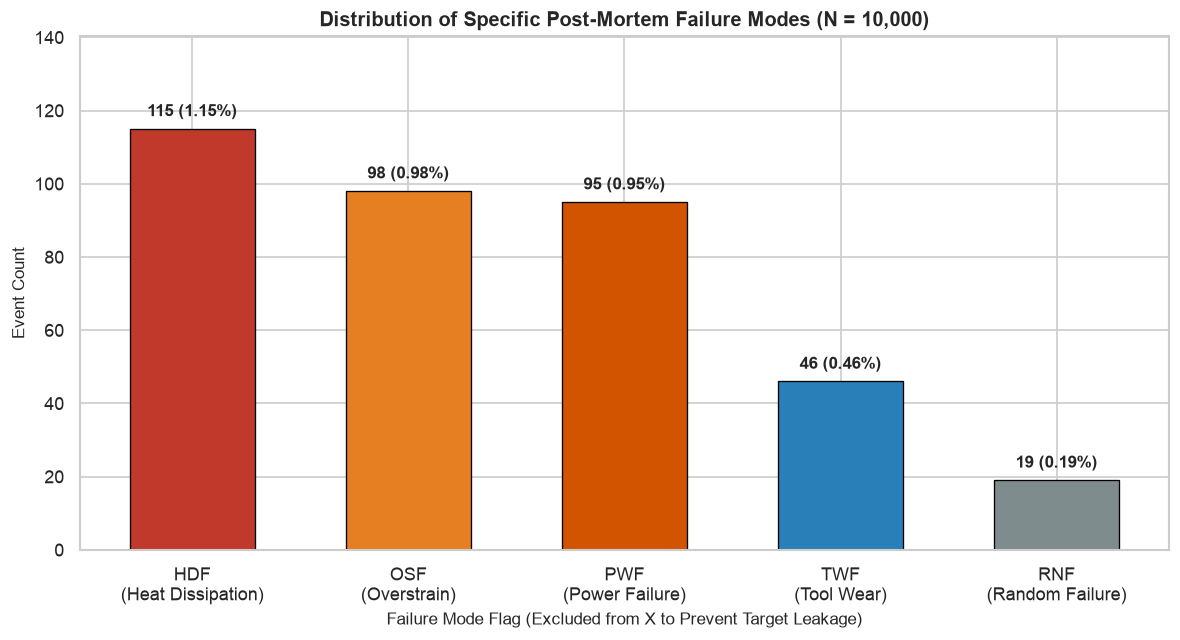

Exported: reports/figures/03_failure_modes_distribution.png


In [7]:
# Failure Modes Breakdown
mode_counts = df_eda[FAILURE_MODES].sum().sort_values(ascending=False)
mode_summary = pd.DataFrame(
    {
        "Failure Mode": mode_counts.index,
        "Count": mode_counts.values,
        "% of Dataset": (mode_counts.values / len(df_eda) * 100).round(2),
        "% of Failure Events (339)": (mode_counts.values / n_pos * 100).round(2),
    }
)
display(mode_summary)

# Audit overlap & dataset quirks
rnf_no_global = int(((df_eda["RNF"] == 1) & (df_eda[TARGET_COLUMN] == 0)).sum())
global_no_mode = int(((df_eda[TARGET_COLUMN] == 1) & (df_eda[FAILURE_MODES].sum(axis=1) == 0)).sum())
multi_mode = int((df_eda[FAILURE_MODES].sum(axis=1) > 1).sum())
print(f"Multi-mode simultaneous failure rows       : {multi_mode}")
print(f"RNF == 1 with Machine failure == 0 (quirk) : {rnf_no_global}")
print(f"Machine failure == 1 with all modes == 0   : {global_no_mode}")

# Export Figure 03: Failure Modes Distribution
fig, ax = plt.subplots(figsize=(10, 5.5))
mode_palette = ["#c0392b", "#e67e22", "#d35400", "#2980b9", "#7f8c8d"]
bars = ax.bar(
    mode_summary["Failure Mode"],
    mode_summary["Count"],
    color=mode_palette,
    width=0.58,
    edgecolor="black",
    linewidth=0.8,
)
ax.set_title("Distribution of Specific Post-Mortem Failure Modes (N = 10,000)", fontweight="bold")
ax.set_xlabel("Failure Mode Flag (Excluded from X to Prevent Target Leakage)")
ax.set_ylabel("Event Count")
ax.set_ylim(0, mode_counts.max() * 1.22)

mode_descriptions = {
    "HDF": "Heat Dissipation",
    "OSF": "Overstrain",
    "PWF": "Power Failure",
    "TWF": "Tool Wear",
    "RNF": "Random Failure",
}
ax.set_xticks(range(len(mode_summary)))
ax.set_xticklabels([f"{m}\n({mode_descriptions[m]})" for m in mode_summary["Failure Mode"]])

for bar, (_, row) in zip(bars, mode_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2.5,
        f"{int(row['Count'])} ({row['% of Dataset']:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.tight_layout()
fig03_path = FIGURES_DIR / "03_failure_modes_distribution.png"
fig.savefig(fig03_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Exported: {fig03_path.relative_to(PROJECT_ROOT)}")

PWF Validation: 95/95 PWF=1 cases fall outside [3.5, 9.0] kW
HDF Validation: 115/115 HDF=1 cases satisfy Delta_T < 8.6 K & Speed < 1380 rpm
OSF Validation: 98/98 OSF=1 cases exceed variant Strain Index limit (11k/12k/13k)


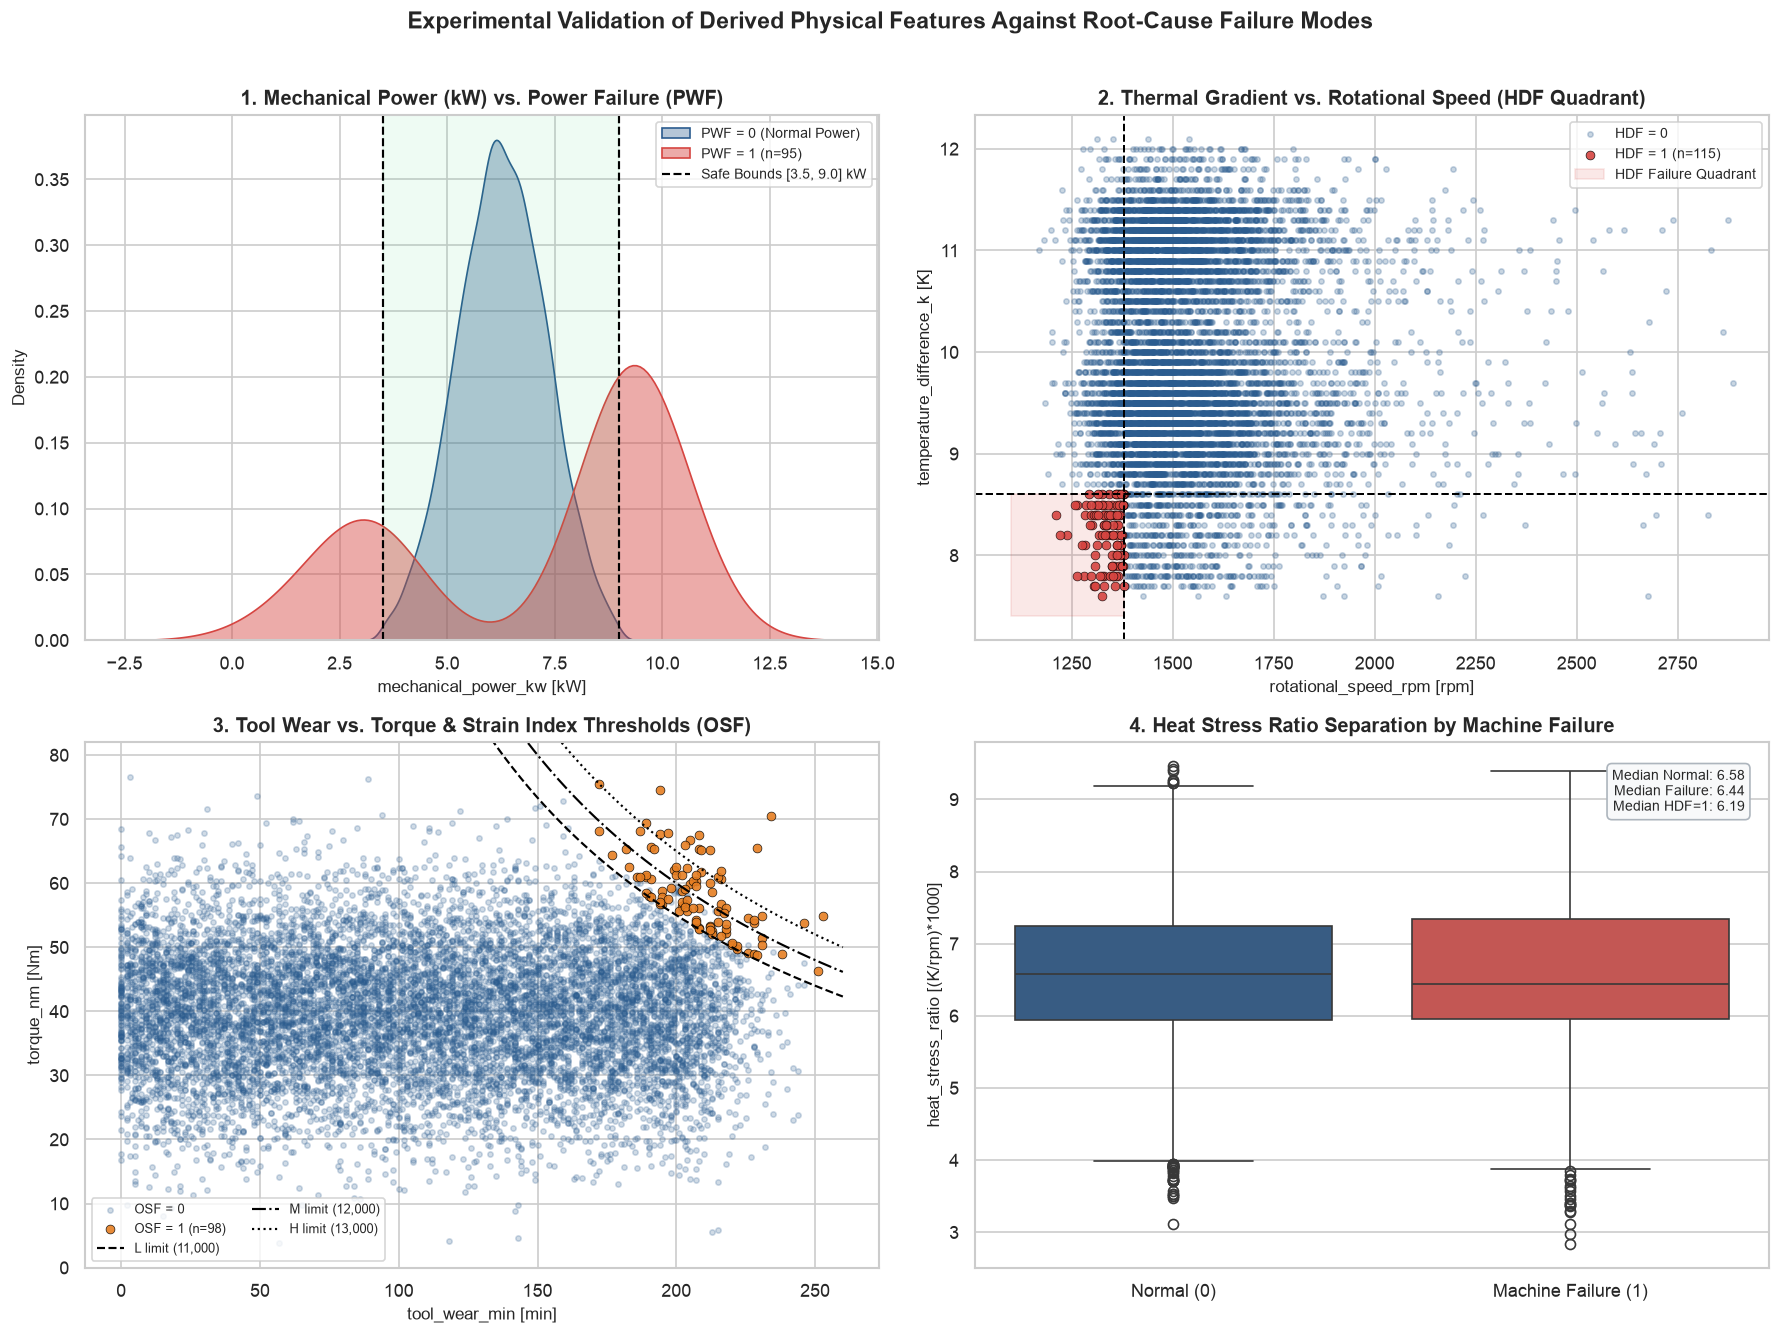

Exported: reports/figures/04_physics_features_separation.png


In [8]:
# Quantitative Causal Validation of the 4 Derived Physical Features
pwf_pos = df_eda.loc[df_eda["PWF"] == 1, "mechanical_power_kw"]
pwf_outside = int(((pwf_pos < 3.5) | (pwf_pos > 9.0)).sum())

hdf_pos = df_eda.loc[df_eda["HDF"] == 1]
hdf_inside_quad = int(
    ((hdf_pos["temperature_difference_k"] < 8.6) & (hdf_pos["rotational_speed_rpm"] < 1380)).sum()
)

osf_pos = df_eda.loc[df_eda["OSF"] == 1]
osf_limits = osf_pos["machine_type"].map({"L": 11_000.0, "M": 12_000.0, "H": 13_000.0})
osf_above_limit = int((osf_pos["strain_index_min_nm"] > osf_limits).sum())

print(f"PWF Validation: {pwf_outside}/{len(pwf_pos)} PWF=1 cases fall outside [3.5, 9.0] kW")
print(f"HDF Validation: {hdf_inside_quad}/{len(hdf_pos)} HDF=1 cases satisfy Delta_T < 8.6 K & Speed < 1380 rpm")
print(f"OSF Validation: {osf_above_limit}/{len(osf_pos)} OSF=1 cases exceed variant Strain Index limit (11k/12k/13k)")

# Export Figure 04: 2x2 Physics Features Separation & Causal Boundaries
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Panel 1: Mechanical Power (kW) vs PWF
sns.kdeplot(
    data=df_eda[df_eda["PWF"] == 0],
    x="mechanical_power_kw",
    fill=True,
    alpha=0.35,
    color="#2b5c8f",
    label="PWF = 0 (Normal Power)",
    ax=axes[0, 0],
)
sns.kdeplot(
    data=df_eda[df_eda["PWF"] == 1],
    x="mechanical_power_kw",
    fill=True,
    alpha=0.45,
    color="#d64541",
    label=f"PWF = 1 (n={len(pwf_pos)})",
    ax=axes[0, 0],
)
axes[0, 0].axvline(3.5, color="black", linestyle="--", linewidth=1.3, label="Safe Bounds [3.5, 9.0] kW")
axes[0, 0].axvline(9.0, color="black", linestyle="--", linewidth=1.3)
axes[0, 0].axvspan(3.5, 9.0, color="#2ecc71", alpha=0.08)
axes[0, 0].set_title("1. Mechanical Power (kW) vs. Power Failure (PWF)", fontweight="bold")
axes[0, 0].set_xlabel("mechanical_power_kw [kW]")
axes[0, 0].legend(loc="upper right", fontsize=8.5)

# Panel 2: Delta T vs Rotational Speed (HDF Quadrant)
hdf_0 = df_eda[df_eda["HDF"] == 0]
hdf_1 = df_eda[df_eda["HDF"] == 1]
axes[0, 1].scatter(
    hdf_0["rotational_speed_rpm"],
    hdf_0["temperature_difference_k"],
    s=10,
    alpha=0.25,
    color="#2b5c8f",
    label="HDF = 0",
)
axes[0, 1].scatter(
    hdf_1["rotational_speed_rpm"],
    hdf_1["temperature_difference_k"],
    s=28,
    alpha=0.9,
    color="#d64541",
    edgecolor="black",
    linewidth=0.4,
    label=f"HDF = 1 (n={len(hdf_1)})",
)
axes[0, 1].axvline(1380, color="black", linestyle="--", linewidth=1.2)
axes[0, 1].axhline(8.6, color="black", linestyle="--", linewidth=1.2)
axes[0, 1].fill_between([1100, 1380], 7.4, 8.6, color="#d64541", alpha=0.12, label="HDF Failure Quadrant")
axes[0, 1].set_title("2. Thermal Gradient vs. Rotational Speed (HDF Quadrant)", fontweight="bold")
axes[0, 1].set_xlabel("rotational_speed_rpm [rpm]")
axes[0, 1].set_ylabel("temperature_difference_k [K]")
axes[0, 1].legend(loc="upper right", fontsize=8.5)

# Panel 3: Tool Wear vs Torque (OSF Hyperbolic Strain Boundaries)
osf_0 = df_eda[df_eda["OSF"] == 0]
osf_1 = df_eda[df_eda["OSF"] == 1]
axes[1, 0].scatter(
    osf_0["tool_wear_min"],
    osf_0["torque_nm"],
    s=10,
    alpha=0.22,
    color="#2b5c8f",
    label="OSF = 0",
)
axes[1, 0].scatter(
    osf_1["tool_wear_min"],
    osf_1["torque_nm"],
    s=28,
    alpha=0.9,
    color="#e67e22",
    edgecolor="black",
    linewidth=0.4,
    label=f"OSF = 1 (n={len(osf_1)})",
)
wear_grid = np.linspace(120, 260, 200)
for limit, lstyle, cname in [
    (11_000, "--", "L limit (11,000)"),
    (12_000, "-.", "M limit (12,000)"),
    (13_000, ":", "H limit (13,000)"),
]:
    axes[1, 0].plot(wear_grid, limit / wear_grid, linestyle=lstyle, color="black", linewidth=1.3, label=cname)
axes[1, 0].set_ylim(0, 82)
axes[1, 0].set_title("3. Tool Wear vs. Torque & Strain Index Thresholds (OSF)", fontweight="bold")
axes[1, 0].set_xlabel("tool_wear_min [min]")
axes[1, 0].set_ylabel("torque_nm [Nm]")
axes[1, 0].legend(loc="lower left", fontsize=8, ncol=2)

# Panel 4: Heat Stress Ratio Separation (Conditioned on HDF & Global Machine Failure)
sns.boxplot(
    data=df_eda,
    x=TARGET_COLUMN,
    y="heat_stress_ratio",
    hue=TARGET_COLUMN,
    palette={0: "#2b5c8f", 1: "#d64541"},
    legend=False,
    ax=axes[1, 1],
)
axes[1, 1].set_xticks([0, 1])
axes[1, 1].set_xticklabels(["Normal (0)", "Machine Failure (1)"])
axes[1, 1].set_title("4. Heat Stress Ratio Separation by Machine Failure", fontweight="bold")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("heat_stress_ratio [(K/rpm)*1000]")

med_0 = float(df_eda.loc[df_eda[TARGET_COLUMN] == 0, "heat_stress_ratio"].median())
med_1 = float(df_eda.loc[df_eda[TARGET_COLUMN] == 1, "heat_stress_ratio"].median())
med_hdf = float(df_eda.loc[df_eda["HDF"] == 1, "heat_stress_ratio"].median())
axes[1, 1].text(
    0.97,
    0.95,
    f"Median Normal: {med_0:.2f}\nMedian Failure: {med_1:.2f}\nMedian HDF=1: {med_hdf:.2f}",
    transform=axes[1, 1].transAxes,
    ha="right",
    va="top",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="#f8f9fa", edgecolor="#adb5bd"),
    fontsize=8.5,
)

plt.suptitle("Experimental Validation of Derived Physical Features Against Root-Cause Failure Modes", fontsize=13.5, fontweight="bold", y=1.01)
plt.tight_layout()
fig04_path = FIGURES_DIR / "04_physics_features_separation.png"
fig.savefig(fig04_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Exported: {fig04_path.relative_to(PROJECT_ROOT)}")

---

## 6. Phase E — Asset Variant (`machine_type`) Analysis & Metric Justification

### 6.1 Conditional Risk by Machine Type (`L`, `M`, `H`)
Low-quality variant assets (`L`, 60.0% of fleet) experience faster tool wear accumulation (+5 min per cycle vs +3 min for `M` and +2 min for `H`) and a lower overstrain tolerance ($11{,}000\text{ min}\cdot\text{Nm}$), yielding nearly **twice** the failure rate of `H` variants.

### 6.2 Why Accuracy Is Operationally Invalid (and Why PR-AUC & $F_2$-Score Govern Optimization)
- **Accuracy Paradox:** With a $3.39\%$ failure prevalence ($28.5 : 1$ imbalance), a trivial constant model predicting `0` for every sensor packet achieves **$96.61\%$ Accuracy** while missing **$100\%$** of catastrophic failures.
- **Primary Ranking Metric — PR-AUC (Average Precision):** Evaluates precision-recall trade-offs across all probability thresholds without being artificially inflated by the $9{,}661$ True Negatives.
- **Primary Detection Metric — $F_2$-Score ($\beta = 2$):**
  $$F_2 = \frac{5 \cdot \text{Precision} \cdot \text{Recall}}{4 \cdot \text{Precision} + \text{Recall}}$$
  Weights **Recall $4\times$ higher than Precision**, directly reflecting the asymmetric mining/industrial cost structure where missed failures (False Negatives) cost orders of magnitude more than preventive inspections (False Positives).

In [9]:
variant_table = (
    df_eda.groupby("machine_type")
    .agg(
        Total_Assets=("machine_failure", "count"),
        Fleet_Share_Pct=("machine_failure", lambda s: len(s) / len(df_eda) * 100),
        Failures=("machine_failure", "sum"),
        Failure_Rate_Pct=("machine_failure", lambda s: s.mean() * 100),
        Mean_Tool_Wear=("tool_wear_min", "mean"),
        Mean_Strain_Index=("strain_index_min_nm", "mean"),
    )
    .reindex(["L", "M", "H"])
    .round(2)
)
display(variant_table)

,Total_Assets,Fleet_Share_Pct,Failures,Failure_Rate_Pct,Mean_Tool_Wear,Mean_Strain_Index
machine_type,,,,,,
L,6000,60.00,235,3.92,108.38,4341.48
M,2997,29.97,83,2.77,107.27,4272.30
H,1003,10.03,21,2.09,107.42,4280.86


---

## 7. Phase 1 Initial Baseline — Stratified 5-Fold CV on `train_dev` Only

Per `00_transversal_standards.md` (§2.2) and `02_experimentation_and_benchmarks.md` (§3.2), we establish a linear baseline using `LogisticRegression` encapsulated inside a zero-leakage `Pipeline`:
- **Numeric preprocessing:** `StandardScaler()` fitted independently inside each training fold.
- **Categorical preprocessing:** `OneHotEncoder(drop="first", handle_unknown="ignore")` on `machine_type`.
- **Cross-Validation:** `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` strictly on `data/processed/train_dev.csv` ($N = 8{,}000$; `test_holdout.csv` remains untouched).
- **Reported Metrics:** `ROC-AUC`, `PR-AUC` (Average Precision), `F1-Score`, and `F2-Score` (`fbeta_score(..., beta=2)`), evaluated both for default `class_weight=None` and `class_weight="balanced"` at the standard $0.50$ threshold.

,Model,CV ROC-AUC (mean±std),CV PR-AUC (mean±std),CV F1 (mean±std),CV F2 (mean±std),OOF ROC-AUC,OOF PR-AUC,OOF F1,OOF F2
0,"LogisticRegression (default, class_weight=None)",0.9144 ± 0.0158,0.5011 ± 0.0309,0.3784 ± 0.0478,0.2901 ± 0.0392,0.9136,0.4961,0.3788,0.2901
1,"LogisticRegression (balanced, class_weight='ba...",0.9273 ± 0.0135,0.4741 ± 0.0358,0.2850 ± 0.0170,0.4707 ± 0.0263,0.9263,0.4715,0.2846,0.4706


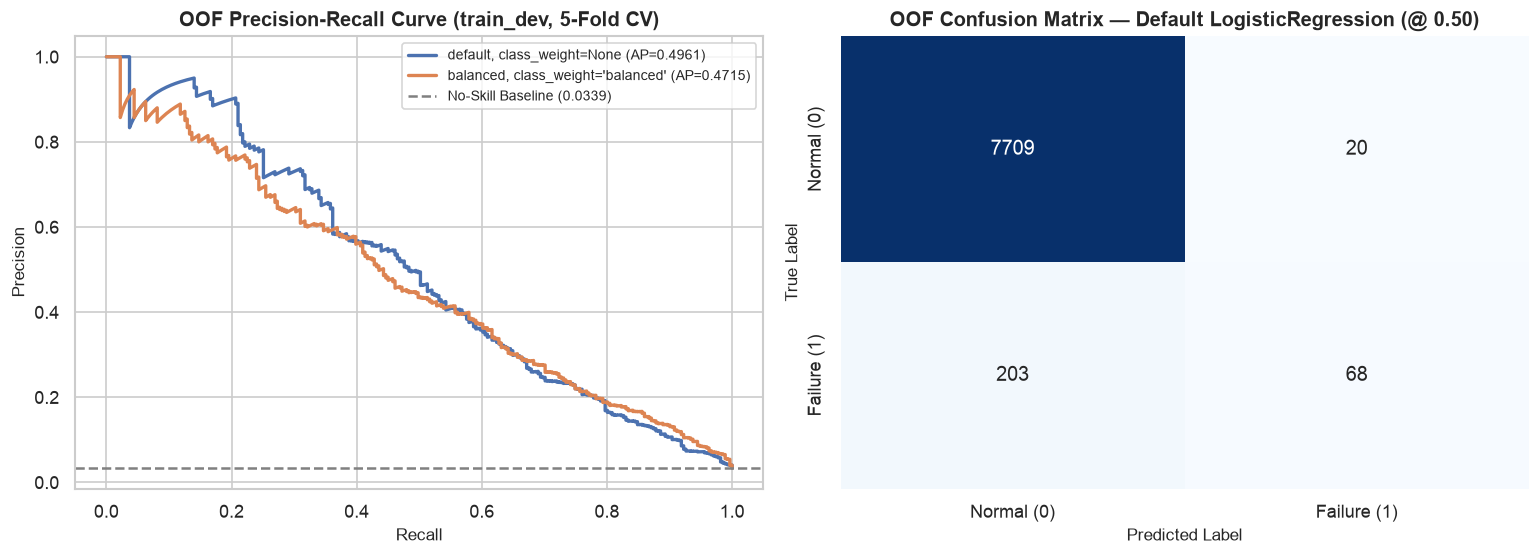

In [10]:
# Load persisted train_dev split strictly (test_holdout remains untouched!)
dev_df = pd.read_csv(train_dev_path)
x_dev = dev_df.drop(columns=[TARGET_COLUMN])
y_dev = dev_df[TARGET_COLUMN]

numeric_features = [
    "air_temperature_k",
    "process_temperature_k",
    "rotational_speed_rpm",
    "torque_nm",
    "tool_wear_min",
] + PHYSICAL_FEATURE_COLUMNS
categorical_features = ["machine_type"]

cv_scheme = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

baseline_results = []
oof_predictions = {}

for label, cw in [
    ("LogisticRegression (default, class_weight=None)", None),
    ("LogisticRegression (balanced, class_weight='balanced')", "balanced"),
]:
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numeric_features),
            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_features),
        ],
        remainder="drop",
    )
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", LogisticRegression(max_iter=1000, class_weight=cw, random_state=RANDOM_STATE)),
        ]
    )

    fold_roc, fold_pr, fold_f1, fold_f2 = [], [], [], []
    for train_idx, val_idx in cv_scheme.split(x_dev, y_dev):
        x_tr, x_va = x_dev.iloc[train_idx], x_dev.iloc[val_idx]
        y_tr, y_va = y_dev.iloc[train_idx], y_dev.iloc[val_idx]

        pipeline.fit(x_tr, y_tr)
        val_prob = pipeline.predict_proba(x_va)[:, 1]
        val_pred = (val_prob >= 0.5).astype(int)

        fold_roc.append(roc_auc_score(y_va, val_prob))
        fold_pr.append(average_precision_score(y_va, val_prob))
        fold_f1.append(f1_score(y_va, val_pred, zero_division=0))
        fold_f2.append(fbeta_score(y_va, val_pred, beta=2, zero_division=0))

    oof_prob = cross_val_predict(pipeline, x_dev, y_dev, cv=cv_scheme, method="predict_proba")[:, 1]
    oof_pred = (oof_prob >= 0.5).astype(int)
    oof_predictions[label] = (oof_prob, oof_pred)

    baseline_results.append(
        {
            "Model": label,
            "CV ROC-AUC (mean±std)": f"{np.mean(fold_roc):.4f} ± {np.std(fold_roc):.4f}",
            "CV PR-AUC (mean±std)": f"{np.mean(fold_pr):.4f} ± {np.std(fold_pr):.4f}",
            "CV F1 (mean±std)": f"{np.mean(fold_f1):.4f} ± {np.std(fold_f1):.4f}",
            "CV F2 (mean±std)": f"{np.mean(fold_f2):.4f} ± {np.std(fold_f2):.4f}",
            "OOF ROC-AUC": round(float(roc_auc_score(y_dev, oof_prob)), 4),
            "OOF PR-AUC": round(float(average_precision_score(y_dev, oof_prob)), 4),
            "OOF F1": round(float(f1_score(y_dev, oof_pred, zero_division=0)), 4),
            "OOF F2": round(float(fbeta_score(y_dev, oof_pred, beta=2, zero_division=0)), 4),
        }
    )

baseline_df = pd.DataFrame(baseline_results)
display(baseline_df)

# Diagnostic Confusion Matrices & PR Curve on OOF Predictions (train_dev only)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

for name, (prob, _) in oof_predictions.items():
    prec, rec, _ = precision_recall_curve(y_dev, prob)
    ap = average_precision_score(y_dev, prob)
    axes[0].plot(rec, prec, linewidth=2, label=f"{name.split('(')[1].rstrip(')')} (AP={ap:.4f})")

axes[0].axhline(y_dev.mean(), color="gray", linestyle="--", label=f"No-Skill Baseline ({y_dev.mean():.4f})")
axes[0].set_title("OOF Precision-Recall Curve (train_dev, 5-Fold CV)", fontweight="bold")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].legend(loc="upper right", fontsize=8.5)

default_key = "LogisticRegression (default, class_weight=None)"
cm = confusion_matrix(y_dev, oof_predictions[default_key][1])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1])
axes[1].set_title("OOF Confusion Matrix — Default LogisticRegression (@ 0.50)", fontweight="bold")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")
axes[1].set_xticklabels(["Normal (0)", "Failure (1)"])
axes[1].set_yticklabels(["Normal (0)", "Failure (1)"])

plt.tight_layout()
plt.show()

---

## 8. Phase 1 Key Conclusions & Handoff to Phase 2

1. **Data Quality & Leakage Control:** `ai4i2020.csv` passes all structural, completeness, and physical range audits `(10000, 14)`. Leakage columns (`UDI`, `Product ID`, `TWF`, `HDF`, `PWF`, `OSF`, `RNF`) are stripped prior to persistence, and `test_holdout.csv` ($N = 2{,}000$, $68$ positives) remains locked.
2. **Causal Physics Validation:** The 4 derived physics features capture the exact mechanistic boundaries of the failures: $100\%$ of `PWF` cases fall outside $[3.5, 9.0]\text{ kW}$, $100\%$ of `HDF` cases occur inside $\Delta T < 8.6\text{ K} \land \omega < 1380\text{ rpm}$, and $100\%$ of `OSF` cases exceed the variant `strain_index_min_nm` limits.
3. **Why Non-Linear Ensembles & Cost Calibration Are Needed in Phase 2:** Because failure boundaries are rectangular/hyperbolic thresholds in feature space (not linear hyperplanes), linear `LogisticRegression` achieves strong global ranking (`ROC-AUC ~0.914`) but moderate `PR-AUC (~0.496)` and low `F2-Score (~0.290)` at threshold $0.50$. Phase 2 will benchmark `RandomForest`, `LightGBM`, and `XGBoost` with probability calibration and Monte Carlo expected-cost threshold optimization $(\theta_1^*, \theta_2^*)$.